# 1. LoRA - BERT 모델을 사용한 PEFT
BERT 모델을 사용하여 PEFT(LoRA) 사용

In [ ]:
!pip install "transformers" "bitsandbytes" "trl" "datasets" "evaluate" "matplotlib-venn"

## 허깅페이스 계정에 로그인

In [1]:
# hugging face login
from huggingface_hub import notebook_login
notebook_login()

/Users/yoonwogud/Desktop/Git/DeepLearning/Part3/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ImportError: The `notebook_login` function can only be used in a notebook (Jupyter or Colab) and you need the `ipywidgets` module: `pip install ipywidgets`.

## BERT 모델 로드

In [ ]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer,TrainingArguments
# 글자 -> 숫자, 분류모델, 학습 도구, 학습 도구

# BERT 로드
base_model = AutoModelForSequenceClassification.from_pretrained(
    "bert-base-uncased", # 인터넷에서 이 모델 다운로드
    num_labels=6 # 6가지 카테고리 중 하나로 분류할거임 (6개의 라벨)
)

base_model

/Users/yoonwogud/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(
Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSdpaSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e

## 데이터세트 로드

In [10]:
from datasets import load_dataset

# 데이터세트
dataset = load_dataset("dair-ai/emotion")
dataset['train'][4]

{'text': 'i am feeling grouchy', 'label': 3}

In [6]:
dataset['test'][0]

{'text': 'im feeling rather rotten so im not very ambitious right now',
 'label': 0}

## 토크나이저 설정

In [ ]:
# 토크나이저
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
# 이 모델에 사용한 토크나이저


def preprocess(example):
    return tokenizer(
        example["text"],
        truncation=True, # 긴 문장 자르기
        padding="max_length", # 패딩 채우기
        max_length=128
    )

tokenized = dataset.map(preprocess, batched=True) # 위에서 만든 preprocess 적용
tokenized = tokenized.rename_column("label", "labels") # 라벨 이름 변경
tokenized.set_format(type="torch", columns=["input_ids", "attention_mask", "labels"])
# list ->Tensor로 변환
train_ds = tokenized["train"] 
eval_ds  = tokenized["validation"]

train_ds[0]

Map:   0%|          | 0/16000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

{'labels': tensor(0),
 'input_ids': tensor([  101,  1045,  2134,  2102,  2514, 26608,   102,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,  

##  PEFT - Lora 설정과 학습

In [ ]:
from peft import LoraConfig, get_peft_model
import evaluate

# LoRA 구성
lora_config = LoraConfig(
    task_type="SEQ_CLS",  # 시퀀스 분류
    r=8,
    lora_alpha=32,
    lora_dropout=0.05,
    target_modules=["query", "key", "value", "output.dense"],
)

# LoRA 적용
model = get_peft_model(base_model, lora_config)

# Trainer 구성
training_args = TrainingArguments(
    output_dir="./lora_bert_mrpc",
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    eval_strategy="steps",
    logging_steps=20,
    save_steps=200,
    save_total_limit=2,
    learning_rate=2e-5,
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    push_to_hub=False,
    report_to="none",
)

# 평가 메트릭
metric = evaluate.load('accuracy')
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = logits.argmax(axis=-1)
    return metric.compute(predictions=preds, references=labels)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=eval_ds,
    tokenizer=tokenizer,
    compute_metrics=compute_metrics
)

# 8. 학습 시작
trainer.train()

/var/folders/53/bz6j7ttj061dc4fqzd1ygd_m0000gn/T/ipykernel_43585/1542683702.py:40: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


  0%|          | 0/3000 [00:00<?, ?it/s]

/Users/yoonwogud/Library/Python/3.9/lib/python/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


{'loss': 1.8884, 'grad_norm': 5.182553291320801, 'learning_rate': 1.9866666666666667e-05, 'epoch': 0.02}


  0%|          | 0/125 [00:00<?, ?it/s]

{'eval_loss': 1.837265133857727, 'eval_accuracy': 0.1025, 'eval_runtime': 19.2452, 'eval_samples_per_second': 103.922, 'eval_steps_per_second': 6.495, 'epoch': 0.02}
{'loss': 1.827, 'grad_norm': 5.315413951873779, 'learning_rate': 1.9733333333333336e-05, 'epoch': 0.04}


... (14 outputs left out)

{'eval_loss': 1.584716796875, 'eval_accuracy': 0.353, 'eval_runtime': 18.5928, 'eval_samples_per_second': 107.569, 'eval_steps_per_second': 6.723, 'epoch': 0.12}
{'loss': 1.6082, 'grad_norm': 4.07576322555542, 'learning_rate': 1.9066666666666668e-05, 'epoch': 0.14}


/Users/yoonwogud/Library/Python/3.9/lib/python/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


  0%|          | 0/125 [00:00<?, ?it/s]

KeyboardInterrupt: 

## 성능 평가 (Evaluate)

In [ ]:
eval_results = trainer.evaluate()
print(f"최종 정확도(Accuracy): {eval_results['eval_accuracy']:.4f}")

## 모델 저장 (Save)
LoRA는 모델 전체가 아니라 학습된 '어댑터(Adapter)' 부분만 저장하면 됩니다. 용량이 매우 작아서 효율적입니다.

In [ ]:
# 학습된 LoRA 모델(어댑터) 저장
save_dir = "./bert-emotion-lora"
model.save_pretrained(save_dir)
tokenizer.save_pretrained(save_dir)

print(f"모델이 '{save_dir}' 폴더에 저장되었습니다.")

## 실제 테스트 (Inference)
저장된 모델이 새로운 문장을 보고 감정을 잘 맞추는지 직접 테스트해 봅니다.

In [ ]:
# 테스트: 문장을 넣어 감정 예측해보기
import torch

# 테스트할 문장
text = "I feel so happy and excited today!"

# 입력 변환
inputs = tokenizer(text, return_tensors="pt").to(model.device)

# 예측
with torch.no_grad():
    logits = model(**inputs).logits
    predicted_class_id = logits.argmax().item()

# 결과 출력 (Emotion 데이터셋 라벨 매핑)
# 0: sadness, 1: joy, 2: love, 3: anger, 4: fear, 5: surprise
labels = ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']
print(f"입력 문장: {text}")
print(f"예측 감정: {labels[predicted_class_id]}")

In [ ]:
import os
from getpass import getpass

a= getpass("api")

# API키 설정
os.environ["HF_TOKEN"] = a

In [ ]:
from huggingface_hub import InferenceClient
import os
client = InferenceClient(
    provider = "together",
    api_key = os.environ["HF_TOKEN"],
)
image = client.text_to_image(
    model = "black-forest-labs/FLUX.1-dev",
    prompt = "안녕",
)

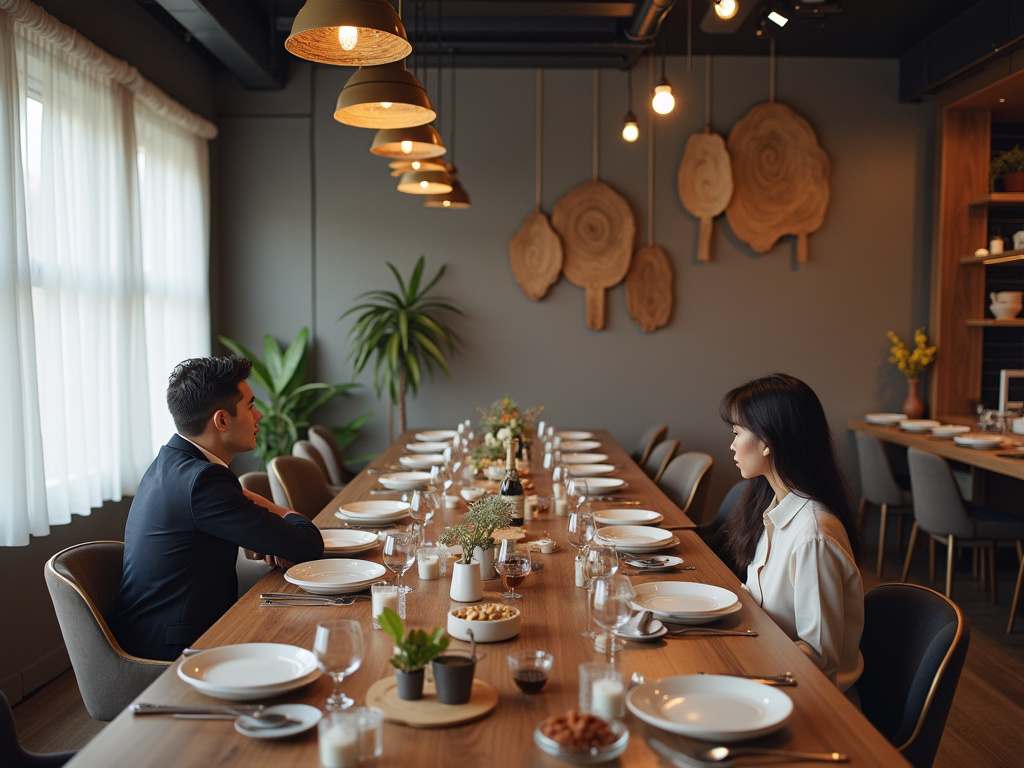

In [27]:
image